In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.io import imread
from skimage.transform import resize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

from skimage import io, color
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier

import skfuzzy as fuzz

### Data loading and FCM preprocessing

In [5]:
categories = ['Diseased', 'Healthy']
train_dir = '..\\Augmentation\\Augmented DataSet\\Train'
test_dir  = '..\\Augmentation\\Augmented DataSet\\Test'


def load_split(base_dir, categories):
    features_list, labels_list = [], []
    for lbl, cat in enumerate(categories):
        print(f'Loading: {cat} from {base_dir}')
        folder = os.path.join(base_dir, cat)
        for fname in os.listdir(folder):
            img = io.imread(os.path.join(folder, fname))
            gray = color.rgb2gray(img)
            resized = resize(gray, (64, 64))
            features_list.append(resized.flatten())
            labels_list.append(lbl)
        print(f'Done: {cat}')
    return np.array(features_list), np.array(labels_list)

X_train_raw, y_train = load_split(train_dir, categories)
X_test_raw,  y_test  = load_split(test_dir, categories)

print('Train:', X_train_raw.shape, '  Test:', X_test_raw.shape)

Loading: Diseased from ..\Augmentation\Augmented DataSet\Train
Done: Diseased
Loading: Healthy from ..\Augmentation\Augmented DataSet\Train
Done: Healthy
Loading: Diseased from ..\Augmentation\Augmented DataSet\Test
Done: Diseased
Loading: Healthy from ..\Augmentation\Augmented DataSet\Test
Done: Healthy
Train: (5600, 4096)   Test: (1400, 4096)


### Fuzzy C-Means Clustering

In [6]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)   
X_test_scaled  = scaler.transform(X_test_raw)         

n_clusters = len(categories)
cntr, u_train, _, _, _, _, _ = fuzz.cluster.cmeans(
    X_train_scaled.T, n_clusters, 2.0, maxiter=100, error=0.005
)

u_test, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    X_test_scaled.T, cntr, 2.0, maxiter=100, error=0.005
)


u_train_features = u_train.T   # shape (n_train_samples, n_clusters)
u_test_features  = u_test.T

X_train = np.hstack([X_train_raw, u_train_features])
X_test  = np.hstack([X_test_raw,  u_test_features])


print('X_train:', X_train.shape, '  X_test:', X_test.shape)

X_train: (5600, 4098)   X_test: (1400, 4098)


### Random Forest Classifier

In [7]:
rf = RandomForestClassifier(
    n_estimators=100, min_samples_split=12,
    min_samples_leaf=5, max_features='log2', random_state=42
)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
acc   = accuracy_score(y_test, y_pred)
prec  = precision_score(y_test, y_pred, average='weighted')
rec   = recall_score(y_test, y_pred, average='weighted')
f1    = f1_score(y_test, y_pred, average='weighted')
tr_acc = accuracy_score(y_train, rf.predict(X_train))

print(classification_report(y_test, y_pred, target_names=categories))
print(f'Test Accuracy  : {acc*100:.2f}%')
print(f'Train Accuracy : {tr_acc*100:.2f}%')
print(f'Precision      : {prec*100:.2f}%')
print(f'Recall         : {rec*100:.2f}%')
print(f'F1-Score       : {f1*100:.2f}%')

              precision    recall  f1-score   support

    Diseased       0.89      0.95      0.92       700
     Healthy       0.94      0.88      0.91       700

    accuracy                           0.91      1400
   macro avg       0.92      0.91      0.91      1400
weighted avg       0.92      0.91      0.91      1400

Test Accuracy  : 91.36%
Train Accuracy : 96.82%
Precision      : 91.53%
Recall         : 91.36%
F1-Score       : 91.35%


### Confusion Matrix

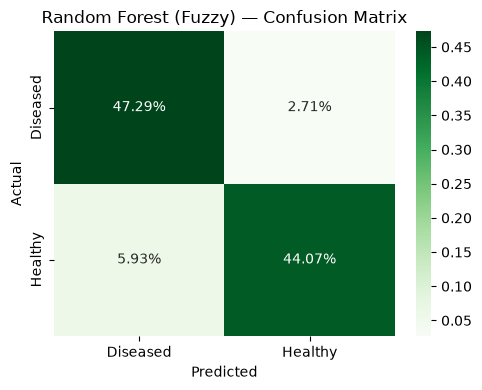

In [8]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm / cm.sum(), annot=True, fmt='.2%',
            cmap='Greens', xticklabels=categories, yticklabels=categories)
plt.title('Random Forest (Fuzzy) — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Live Prediction on Sample Papaya Image

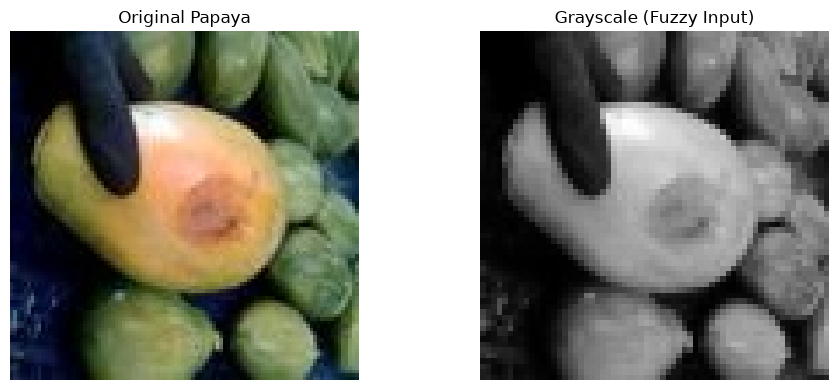

Prediction - Diseased


In [11]:
sample_dir = os.path.join(test_dir, 'Diseased')
sample_path = os.path.join(sample_dir, os.listdir(sample_dir)[450])
orig = io.imread(sample_path)

gray_s = color.rgb2gray(orig)
seg_sample = (resize(gray_s, (64, 64)) * 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(orig)
axes[0].set_title('Original Papaya')
axes[0].axis('off')
axes[1].imshow(seg_sample, cmap='gray')
axes[1].set_title('Grayscale (Fuzzy Input)')
axes[1].axis('off')
plt.tight_layout()
plt.show()


feat_raw = resize(gray_s, (64, 64)).flatten().reshape(1, -1)
feat_scaled = scaler.transform(feat_raw)
u_sample, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
    feat_scaled.T, cntr, 2.0, maxiter=100, error=0.005
)
feat = np.hstack([feat_raw, u_sample.T])  

pred_idx = rf.predict(feat)[0]
probs = rf.predict_proba(feat)[0]
print(f'Prediction - {categories[pred_idx]}')

## Insights 

- **Strong Overall Performance**: This combination achieved a solid Test Accuracy of **~91.4%** with a Train Accuracy of **~96.8%**. The relatively small gap between train and test accuracy indicates the model generalizes well and is not heavily overfitting.
- **Balanced Precision and Recall**: With both precision and recall sitting around **91.5% - 91.4%**, the model effectively balances finding true positives while minimizing false alarms, which is crucial for reliable disease detection.
- **Production Readiness**: Because this pipeline uses simple grayscale resizing combined with shallow machine learning (FCM + RF), it is highly interpretable, lightweight, and fast for inference, making it an excellent candidate for live deployment.


In [12]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.ensemble import RandomForestClassifier


class FuzzyCMeansFeaturizer(BaseEstimator, TransformerMixin):
    """Turns raw pixel vectors into FCM membership features."""
    def __init__(self, n_clusters=2, m=2.0, maxiter=100, error=0.005):
        self.n_clusters = n_clusters
        self.m = m
        self.maxiter = maxiter
        self.error = error

    def fit(self, X, y=None):
        self.scaler_ = MinMaxScaler()
        X_scaled = self.scaler_.fit_transform(X)
        self.cntr_, _, _, _, _, _, _ = fuzz.cluster.cmeans(
            X_scaled.T, self.n_clusters, self.m,
            maxiter=self.maxiter, error=self.error
        )
        return self

    def transform(self, X):
        X_scaled = self.scaler_.transform(X)
        u, _, _, _, _, _ = fuzz.cluster.cmeans_predict(
            X_scaled.T, self.cntr_, self.m,
            maxiter=self.maxiter, error=self.error
        )
        return u.T   # shape: (n_samples, n_clusters)


class PassthroughTransformer(BaseEstimator, TransformerMixin):
    """Passes raw pixel features through unchanged."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X


#  raw pixels + FCM membership into one feature set
feature_union = FeatureUnion([
    ('raw_pixels', PassthroughTransformer()),
    ('fuzzy_membership', FuzzyCMeansFeaturizer(n_clusters=2))
])

# pipeline
fuzzy_rf_pipeline = Pipeline([
    ('features', feature_union),
    ('rf', RandomForestClassifier(n_estimators=100, min_samples_split=12,
                                    min_samples_leaf=5, max_features='log2',
                                    random_state=42))])

In [13]:
fuzzy_rf_pipeline.fit(X_train_raw, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('raw_pixels', ...), ('fuzzy_membership', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [14]:
y_pred = fuzzy_rf_pipeline.predict(X_test_raw)

In [15]:
import joblib
joblib.dump(fuzzy_rf_pipeline, 'model.pkl')

['model.pkl']

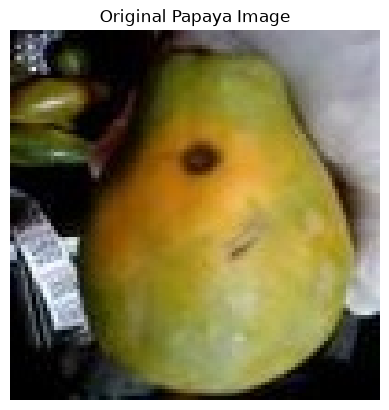

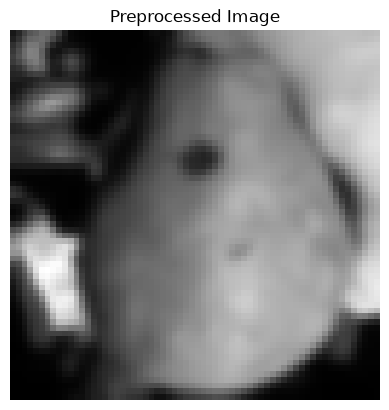

Prediction Probabilities:
Diseased: 91.82%
Healthy: 8.18%

Final Prediction: Diseased


In [18]:
import random
categories = ['Diseased', 'Healthy']


sample_dir = os.path.join(test_dir, 'Diseased')
sample_file = random.choice(os.listdir(sample_dir))
sample_path = os.path.join(sample_dir, sample_file)

sample_img = imread(sample_path)

plt.imshow(sample_img)
plt.axis('off')
plt.title('Original Papaya Image')
plt.show()


gray_sample = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
blurred_sample = cv2.GaussianBlur(gray_sample, (7, 7), 0)
resized_sample = resize(blurred_sample, (64, 64))

plt.imshow(resized_sample, cmap='gray')
plt.axis('off')
plt.title('Preprocessed Image')
plt.show()


raw_vec = resized_sample.flatten().reshape(1, -1)

pred_idx = fuzzy_rf_pipeline.predict(raw_vec)[0]
probs = fuzzy_rf_pipeline.predict_proba(raw_vec)[0]

print("Prediction Probabilities:")
for idx, cat_name in enumerate(categories):
    print(f"{cat_name}: {probs[idx] * 100:.2f}%")

print(f"\nFinal Prediction: {categories[pred_idx]}")